In [31]:
# Imports necessary libraries
import pandas as pd
import numpy as np
import glob
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import statsmodels.api as sm

# Initializes dataframes
a250_df = pd.DataFrame()
s275_df = pd.DataFrame()

# Finds all the files from the experiment
ag_files = sorted(glob.glob('raw_data/CDOM_processed/ag/CDOM_fitted_offset_HF_T*.csv'))
slope_files = sorted(glob.glob('raw_data/CDOM_processed/slopes/CDOM_fitted_offset_HF_T*.csv'))

# Concatenates all the CSV files into one dataframe
a250_df = pd.concat((pd.read_csv(file, usecols=['Wavelength', '250', '254']).assign(filename=file) 
                    for file in ag_files), ignore_index=True)
s275_df = pd.concat((pd.read_csv(file, usecols=['Slopes', 'S275295']).assign(filename=file) 
                    for file in slope_files), ignore_index=True)
DOC_df = pd.read_table('raw_data/DOC_T0_to_T8.txt')

# Rearranges dataframe to sort data into columns by sample type
sample_list = ['GFF_LC', 'GFC_LC', 'GFF_DC', 'GFC_DC']
a250_df_sorted = pd.DataFrame(columns=sample_list)
s275_df_sorted = pd.DataFrame(columns=sample_list)
DOC_df_sorted = pd.DataFrame(columns=sample_list)
SUVA_df_sorted = pd.DataFrame(columns=sample_list)

for sample in sample_list:
    temp_a250_df = a250_df[a250_df['Wavelength'].str.endswith(sample)]
    temp_s275_df = s275_df[s275_df['Slopes'].str.endswith(sample)]
    temp_DOC_df = DOC_df[DOC_df['Sample name'].str.endswith(sample)]

    a250_df_sorted[sample] = temp_a250_df['250'].reset_index(drop=True)
    s275_df_sorted[sample] = temp_s275_df['S275295'].reset_index(drop=True)
    DOC_df_sorted[sample] = temp_DOC_df[' DOC (uM)'].reset_index(drop=True)


    # SUVA254 = CDOM (ag254) / DOC (mg/L)
    SUVA_df_sorted[sample] = ((temp_a250_df['254'].reset_index(drop=True) / np.log(10)) /
                              (temp_DOC_df[' DOC (uM)'].reset_index(drop=True) * 0.012))
    

# Deletes first row
a250_df_sorted.iloc[0] = np.nan
s275_df_sorted.iloc[0] = np.nan

point_size = 50

SUVA_df_sorted
# print(temp_a250_df['254'])
# print(temp_DOC_df[' DOC (uM)'] * 0.012)
# SUVA_df_sorted
# # Fills GFF samples with raw data from 071625
# a250_df_sorted.loc[0, 'GFF_LC'] = 277.4737
# a250_df_sorted.loc[0, 'GFF_DC'] = 277.4737

# s275_df_sorted.loc[0, 'GFF_LC'] = 0.011166
# s275_df_sorted.loc[0, 'GFF_LC'] = 0.011166

,GFF_LC,GFC_LC,GFF_DC,GFC_DC
0,6.974507,6.983134,6.576325,6.821835
1,7.378253,7.529288,6.887457,7.120199
2,7.294175,7.607884,6.856080,7.066526
3,7.584642,7.833125,6.828730,7.162445
4,7.885838,8.135472,6.886316,7.224826
5,7.957984,8.172655,6.775645,7.212781
6,7.898483,7.568386,6.998501,7.206184
7,8.054645,8.385355,6.950565,7.071068
8,7.772251,8.209567,7.000891,7.161419


In [ ]:
# DOC df single graph
x = np.arange(len(a250_df_sorted))

fig, ax = plt.subplots(figsize=(6,6))

for i, sample in enumerate(sample_list):
    if (i <= 1):
        c='#0077FF'
    else:
        c='red'
    if (i % 2 == 0):
        m='v'
    else:
        m='o'

    ax.scatter(x, a250_df_sorted[sample], color=c, marker=m, s=point_size, label=sample, alpha=0.7)

ax.legend(ncols=2, loc='upper right', facecolor="#DFDFDF", edgecolor='black')

plt.title('a$_{250}$ Over Time')

plt.ylabel('a$_{250}$ (m$^{-1}$)')
plt.ylim(239.4, 300.4)

plt.xlabel('Sampling Day')
plt.xticks(np.arange(0,9)) # Sets ticks to be whole numbers 
plt.xlim(-0.1, 8.5)

plt.grid(color='#DDDDDD', linestyle='--', linewidth=0.5)

# x = sm.add_constant(x, prepend=False)
# reg = sm.OLS(DOC_df_sorted['GFF_LC'].iloc[1:], x[1:]).fit()
# print(reg.summary())

# plt.show()

In [ ]:
# SUVA df single plot
x = np.arange(len(s275_df_sorted))

fig, ax = plt.subplots(figsize=(6,6))

for i, sample in enumerate(sample_list):
    if (i <= 1):
        c='#0077FF'
    else:
        c='red'
    if (i % 2 == 0):
        m='v'
    else:
        m='o'

    ax.scatter(x, s275_df_sorted[sample], color=c, marker=m, s=point_size, label=sample, alpha=0.7)

ax.legend(ncols=2, loc='upper right', facecolor="#DFDFDF", edgecolor='black')

plt.title('S$_{275-295}$ Over Time')

plt.ylabel('S$_{275-295}$ (nm$^{-1}$)')
plt.ylim(0.0105, 0.0117)

plt.xlabel('Sampling Day')
plt.xticks(np.arange(0,9)) # Sets ticks to be whole numbers 
plt.xlim(-0.1, 8.5)

plt.grid(color='#DDDDDD', linestyle='--', linewidth=0.5)

# x = sm.add_constant(x, prepend=False)
# reg = sm.OLS(s275_df_sorted['GFF_LC'].iloc[1:], x[1:]).fit()
# print(reg.summary())

# plt.show()


Text(0.5, 0.04, 'Sampling Day')

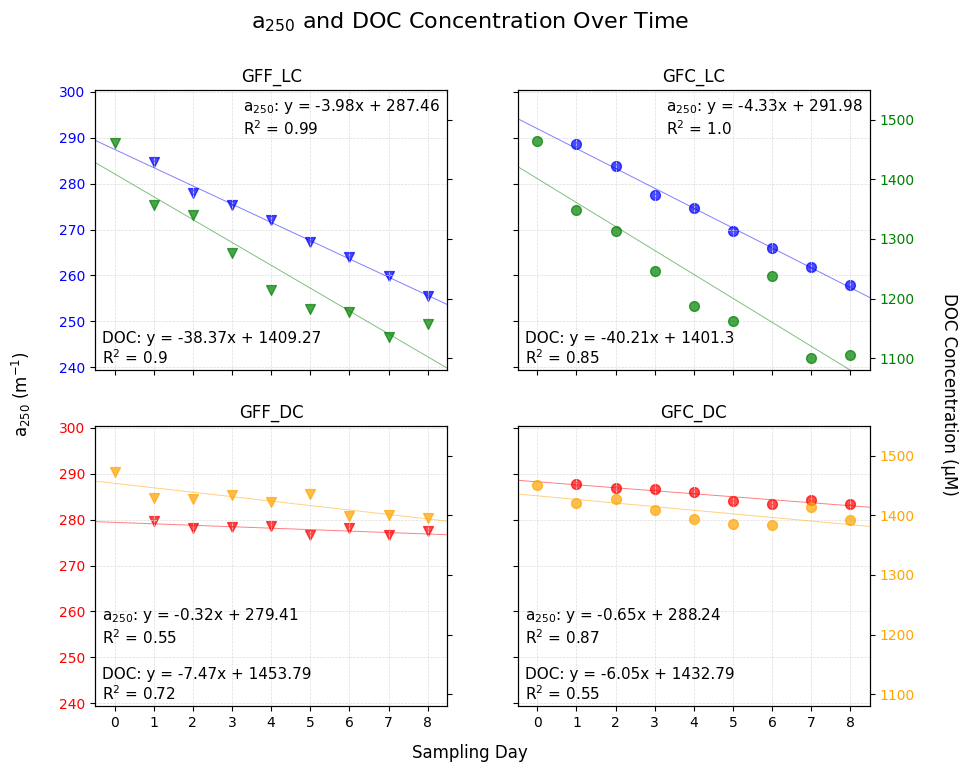

In [33]:
# DOC multiplot with a250 and DOC displayed
x = np.arange(len(a250_df_sorted))

fig, axs = plt.subplots(2, 2, figsize=(10,8), sharex=True, sharey=True)

for i, ax in enumerate(axs.flat):
    if (i % 2 == 0):
        m = 'v'
    else:
        m = 'o'
    if (i <= 1):
        c_a250 ='blue'
        c_DOC = 'green'
    else:
        c_a250 = 'red'
        c_DOC = 'orange'
        
    ax.scatter(x, a250_df_sorted[sample_list[i]], color=c_a250, marker=m, s=point_size, alpha=0.7)
    ax.set(xlim=(-0.5, 8.5), xticks=np.arange(0,9), ylim=(239.4, 300.4), title=sample_list[i])
    ax.tick_params(axis='y', labelcolor=c_a250)

    ax_twin = ax.twinx()

    ax_twin.scatter(x, DOC_df_sorted[sample_list[i]], color=c_DOC, marker=m, s=point_size, alpha=0.7)
    ax_twin.set(ylim=(1080, 1550))
    ax_twin.tick_params(axis='y', labelcolor=c_DOC)
    
    ax.grid(color='#DDDDDD', linestyle='--', linewidth=0.5)

    ax.label_outer()
    ax_twin.label_outer()

    x_reg = sm.add_constant(x, prepend=False)

    # Generates regression lines for DOC and a250
    reg_a250 = sm.OLS(a250_df_sorted[sample_list[i]].iloc[1:], x_reg[1:]).fit()
    reg_DOC = sm.OLS(DOC_df_sorted[sample_list[i]], x_reg).fit()

    # Obtains slope and y-intercept of regression lines - used for plotting
    slope_a250, y_int_a250 = reg_a250.params.iloc[0], reg_a250.params.iloc[1]
    slope_DOC, y_int_DOC = reg_DOC.params.iloc[0], reg_DOC.params.iloc[1]

    # Getting values to help define the position of text 
    x_max, x_min = ax.get_xlim()[1], ax.get_xlim()[0]
    y_max, y_min = ax.get_ylim()[1], ax.get_ylim()[0]
    x_range, y_range = x_max - x_min, y_max - y_min

    # Plotting the two linear regressions
    x_line = np.linspace(x_min, x_max, num=len(a250_df_sorted))
    ax.plot(x_line, y_int_a250 + slope_a250 * x_line, color=c_a250, lw=0.7, alpha=0.5)
    ax_twin.plot(x_line, y_int_DOC + slope_DOC * x_line, color=c_DOC, lw=0.7, alpha=0.5)

    # Generating text for r2 and equations
    r2_text_a250 = 'R$^{2}$ = ' + str(round(reg_a250.rsquared, 2))
    r2_text_DOC = 'R$^{2}$ = ' + str(round(reg_DOC.rsquared, 2))

    eq_text_a250 = 'y = ' + str(round(slope_a250, 2)) + 'x' + ' + ' + str(round(y_int_a250, 2))
    eq_text_DOC = 'y = ' + str(round(slope_DOC, 2)) + 'x' + ' + ' + str(round(y_int_DOC, 2))

    if i > 1:
        ax.text(x_min + 0.02 * x_range, y_min + 0.02 * y_range, 
                'a$_{250}$: ' + eq_text_a250 + '\n' + r2_text_a250 + '\n\nDOC: ' + eq_text_DOC + '\n' + r2_text_DOC,
                fontsize=11)
    else:
        ax.text(x_min + 0.02 * x_range, y_min + 0.02 * y_range, 
                'DOC: ' + eq_text_DOC + '\n' + r2_text_DOC,
                fontsize=11)
        ax.text(x_max - 0.58 * x_range, y_max - 0.16 * y_range,
                'a$_{250}$: ' + eq_text_a250 + '\n' + r2_text_a250,
                fontsize=11)



fig.suptitle('a$_{250}$ and DOC Concentration Over Time', fontsize=16)

# Y labels - using .text because it's more customizable
fig.text(0.04, 0.5, 'a$_{250}$ (m$^{-1}$)', va='center', rotation=90, fontsize=12)
fig.text(0.97, 0.5, 'DOC Concentration (μM)', va='center', rotation=270, fontsize=12)
fig.supxlabel('Sampling Day', y=0.04)

Text(0.5, 0.04, 'Sampling Day')

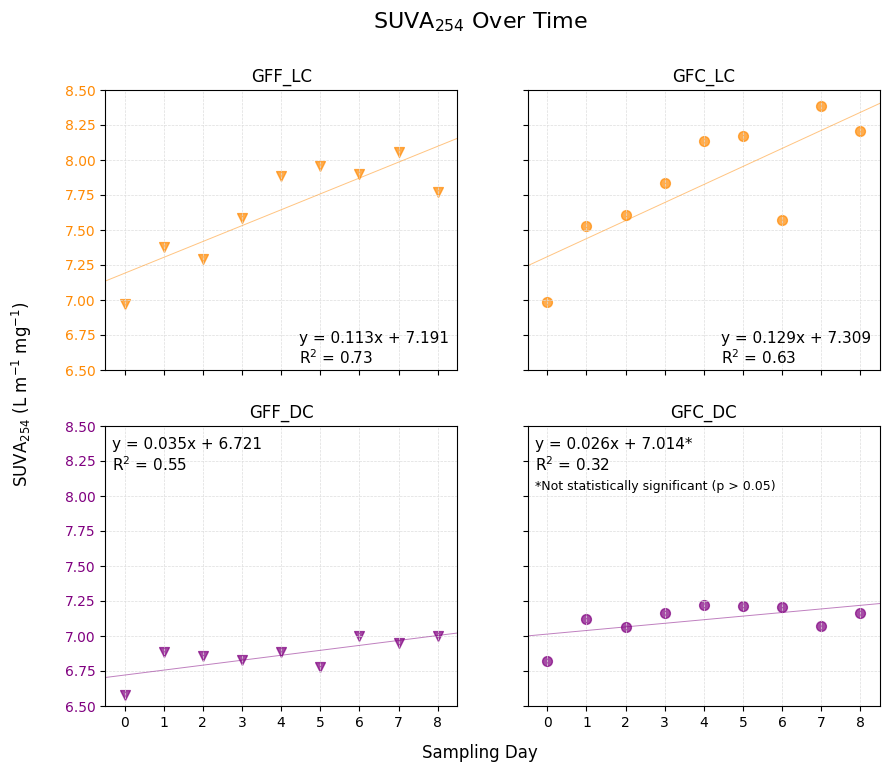

In [35]:
# SUVA multiplot
x = np.arange(len(s275_df_sorted))

fig, axs = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)

for i, ax in enumerate(axs.flat):
    if (i % 2 == 0):
        m = 'v'
    else:
        m = 'o'
    if (i <= 1):
        c_SUVA = "#FF8A04"
        c_s275 = "#FF00E6"
    else:
        c_SUVA = 'purple'
        c_s275 = "#6F3B00"
        
    # ax.scatter(x, s275_df_sorted[sample_list[i]], color=c_s275, marker=m, s=point_size, alpha=0.7)
    # ax.set(xlim=(-0.5, 8.5), xticks=np.arange(0,9), ylim=(0.0105, 0.0120), title=sample_list[i])
    # ax.tick_params(axis='y', labelcolor=c_s275)

    # ax_twin = ax.twinx()

    ax.scatter(x, SUVA_df_sorted[sample_list[i]], color=c_SUVA, marker=m, s=point_size, alpha=0.7)
    ax.set(xlim=(-0.5, 8.5), xticks=np.arange(0,9), ylim=(6.5,8.5), title=sample_list[i])
    ax.tick_params(axis='y', labelcolor=c_SUVA)

    ax.grid(color='#DDDDDD', linestyle='--', linewidth=0.5)

    ax.label_outer()
    # ax_twin.label_outer()

    x_reg = sm.add_constant(x, prepend=False)

    # reg_s275 = sm.OLS(s275_df_sorted[sample_list[i]].iloc[1:], x_reg[1:]).fit()
    reg_SUVA = sm.OLS(SUVA_df_sorted[sample_list[i]], x_reg).fit()

    # slope_s275, y_int_s275 = reg_s275.params.iloc[0], reg_s275.params.iloc[1]
    slope_SUVA, y_int_SUVA = reg_SUVA.params.iloc[0], reg_SUVA.params.iloc[1]

    x_max, x_min = ax.get_xlim()[1], ax.get_xlim()[0]
    y_max, y_min = ax.get_ylim()[1], ax.get_ylim()[0]
    x_range, y_range = x_max - x_min, y_max - y_min

    x_line = np.linspace(x_min, x_max, num=len(s275_df_sorted))
    # ax.plot(x_line, y_int_s275 + slope_s275 * x_line, color=c_s275, lw=0.7, alpha=0.5)
    ax.plot(x_line, y_int_SUVA + slope_SUVA * x_line, color=c_SUVA, lw=0.7, alpha=0.5)

    # r2_text_s275 = 'R$^{2}$ = ' + str(round(reg_s275.rsquared, 2))
    r2_text_SUVA = 'R$^{2}$ = ' + str(round(reg_SUVA.rsquared, 2))
    # eq_text_s275 = 'y = ' + str(round(slope_s275, 7)) + 'x' + ' + ' + str(round(y_int_s275, 5))
    eq_text_SUVA = 'y = ' + str(round(slope_SUVA, 3)) + 'x' + ' + ' + str(round(y_int_SUVA, 3))

    if i > 1:
        if i == 3:
            eq_text_SUVA = str(eq_text_SUVA) + '*'
            ax.text(x_min + 0.02 * x_range, y_min + 0.77 * y_range,
                    '*Not statistically significant (p > 0.05)',
                    fontsize=9)
        ax.text(x_min + 0.02 * x_range, y_min + 0.84 * y_range, 
            eq_text_SUVA + '\n' + r2_text_SUVA, 
            fontsize=11)
    else: 
        ax.text(x_min + 0.55 * x_range, y_min + 0.02 * y_range, 
            eq_text_SUVA + '\n' + r2_text_SUVA, 
            fontsize=11)

fig.suptitle('SUVA$_{254}$ Over Time', fontsize=16)
# fig.text(0.04, 0.5, 'S$_{275-295}$ (nm$^{-1}$)', va='center', rotation=90, fontsize=12)
fig.text(0.03, 0.5, 'SUVA$_{254}$ (L m$^{-1}$ mg$^{-1}$)', va='center', rotation=90, fontsize=12)
fig.supxlabel('Sampling Day', y=0.04)